# Eye-label check (focus: sub-05, sub-04)

**Why.** The run labels of several subjects were wrong and were recovered by fitting each run alone with each stimulus design and keeping the one that gives sensible maps (project notes). This procedure identifies the **stimulus** of a run (bars / rings / wedges), **not the eye**: the retinotopic maps of both eyes look the same. sub-05 (6/8 runs relabelled, raw data recovered from dcm2niix outputs) is the only amblyope with a clear preference for the amblyopic eye (V2-LO2), and sub-04 (6/8 relabelled) has no dominance. Could some runs have the wrong eye?

**Relabelling of sub-05 (notes):** RE: Bars01 → Bars01, Rings → Wedges, Bars02 → Rings, Wedges → Bars02; LE: Bars01 → Bars01, Wedges → Rings, Rings → Bars02, Bars02 → Wedges. Every run kept its eye label.

**What the data can and cannot say.** The OD maps are reproducible (Figure 3 of v9), so each run carries an eye-specific spatial pattern. This allows to detect runs whose eye label is **inconsistent with the other runs** of the subject. A **global swap** (all runs of both eyes exchanged) cannot be detected from the maps (only the sign of the whole map changes); it can only be hinted by the fit quality (in the amblyopes, the amblyopic eye has a lower pRF R²) and by the acquisition order.

| test | question | what a mislabel looks like |
|---|---|---|
| 1. Per-run OD maps | for each stimulus r, map `β_FE,r − β_AE,r`; 4 × 4 correlations between the 4 maps | a pair of runs (FE, AE) of one stimulus with swapped eyes gives a map **anti-correlated** with the other 3 |
| 1b. Sign search | which combination of flipped pairs maximises the agreement of the 4 maps? | best combination ≠ the labelled one |
| 2. Bars partition | the 4 bars runs (FE1, FE2, AE1, AE2): which grouping in 2 pairs gives the most similar maps? | labelled grouping "by eye" not the best |
| 3. Fit quality per run | R² of each run with its own eye's pRF prediction | runs labelled AE better than runs labelled FE (opposite of the other amblyopes) → hint of a global swap |
| 4. Acquisition order | times / series numbers of the 8 runs (BIDS json), eye scanned first (notes) | labelled eyes not in contiguous blocks, or block order ≠ notes |

Every test is run on **all subjects**: the subjects with correct labels give the reference distribution (in particular sub-17 and sub-16, 8/8 runs correctly labelled). Read only; nothing is written in the data folders; figures in `Desktop/fig_od` (prefix `eyecheck_`).

## Setup (cells copied from v9: settings, helpers, vertex data)

In [1]:
# Stop warnings
import warnings
warnings.filterwarnings("ignore")

# General imports
import os
import sys
import numpy as np
import pandas as pd
from scipy import stats, integrate
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Personal imports
sys.path.append("{}/../../analysis_code/utils".format(os.getcwd()))
from settings_utils import load_settings
from pycortex_utils import set_pycortex_config_file, get_rois, load_surface_pycortex
from plot_utils import plotly_template

In [2]:
# Directories
main_dir = '/Users/uriel/disks/meso_shared'
project_dir = 'amblyo7T_prf'
pp_dir = '{}/{}/derivatives/pp_data'.format(main_dir, project_dir)
fig_dir = '/Users/uriel/Desktop/fig_od'
cache_dir = '/Users/uriel/Desktop/fig_od/od_glm_common_cache'       # per-run GLM sums (od_glm_common_analysis.ipynb)
os.makedirs(fig_dir, exist_ok=True)

# Settings
base_dir = os.path.abspath(os.path.join(os.getcwd(), "../../"))
settings = load_settings([os.path.join(base_dir, project_dir, f) for f in
                          ["settings.yml", "prf-analysis.yml", "figure-settings.yml"]])
analysis_info = settings[0]
patients = analysis_info['group-patient']
controls = analysis_info['group-control']
subjects = analysis_info['subjects']
maps_names_css = analysis_info['maps_names_css']
maps_names_css_stats = analysis_info['maps_names_css_stats']
maps_names_css_od = analysis_info['maps_names_css_od']

# Analysis
task = 'BarsBarsRingsWedges'
file_spec = '{}/{}/fsnative/prfmodel/prf_derivatives/{}_task-{}{}_hemi-{}_fmriprep_dct_psc_concat_prf-css_{}.func.gii'
rois_to_keep = ['V1', 'V2', 'V3', 'V4', 'V3A', 'V3B', 'LO1', 'LO2']
eyes = {'L': 'LeftEye', 'R': 'RightEye'}

# prf_analysis filters (applied to both eyes)
ecc_th = analysis_info['ecc_th']
size_th = analysis_info['size_th']
n_th = analysis_info['n_th']
rsqr_th = analysis_info['rsqr_th']
amp_th = analysis_info['prf_amp_th']
amp_th = amp_th['psc'] if isinstance(amp_th, dict) else amp_th
stats_th = analysis_info['stats_th']
p_name = 'corr_pvalue_5pt' if stats_th == 0.05 else 'corr_pvalue_1pt'

# Amblyopic eye of each patient
participants = pd.read_csv('{}/{}/participants.tsv'.format(main_dir, project_dir), sep='\t')
ambly_eye = {s: str(e).split(' ')[0] for s, e in zip(participants.participant_id, participants.amblyopic_eye)
             if str(e).split(' ')[0] in ('L', 'R')}

# Eye scanned first (read only: sourcedata/participant-mapping.md + participant_mapping.tsv)
src_dir = '{}/{}/sourcedata'.format(main_dir, project_dir)
mapping = pd.read_csv('{}/participant_mapping.tsv'.format(src_dir), sep='\t', dtype=str).dropna(subset=['initials'])
initials_to_sub = {i.strip(): b.strip() for i, b in zip(mapping.initials, mapping.bids_name)}
first_eye = {}
with open('{}/participant-mapping.md'.format(src_dir)) as f:
    for line in f:
        if 'eye first' in line:
            initials, txt = line.split(',', 1)
            first_eye[initials_to_sub[initials.strip()]] = 'L' if 'LEFT' in txt.upper() else 'R'

# Pycortex database (ROIs)
cortex_dir = '{}/{}/derivatives/pp_data/cortex'.format(main_dir, project_dir)
set_pycortex_config_file(cortex_dir)

In [3]:
def bh_fdr(p):
    """Benjamini-Hochberg FDR correction."""
    p = np.asarray(p, float)
    o = np.argsort(p)
    q = p[o] * len(p) / (np.arange(len(p)) + 1)
    q = np.minimum.accumulate(q[::-1])[::-1]
    out = np.empty_like(q)
    out[o] = np.minimum(q, 1)
    return out


def wcorr(x, y, w):
    """Weighted rank correlation: Pearson correlation of the ranks of x and y, each vertex weighted by w."""
    x, y, w = stats.rankdata(x), stats.rankdata(y), np.asarray(w, float)
    if np.sum(w) == 0:
        return np.nan
    mx, my = np.sum(w * x) / np.sum(w), np.sum(w * y) / np.sum(w)
    return np.sum(w * (x - mx) * (y - my)) / np.sqrt(np.sum(w * (x - mx) ** 2) * np.sum(w * (y - my) ** 2))


def stars(p):
    return '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else ''


def bf10_ttest(x, h0=0, r=np.sqrt(2) / 2):
    """JZS Bayes factor BF10 of a one-sample t-test (Rouder et al. 2009), Cauchy prior of scale r on the effect size."""
    x = np.asarray(x, float)
    x = x[np.isfinite(x)] - h0
    n, v = x.size, x.size - 1
    t = x.mean() / (x.std(ddof=1) / np.sqrt(n))
    null = (1 + t ** 2 / v) ** (-(v + 1) / 2)
    alt = integrate.quad(lambda g: (1 + n * g * r ** 2) ** -0.5
                         * (1 + t ** 2 / ((1 + n * g * r ** 2) * v)) ** (-(v + 1) / 2)
                         * (2 * np.pi) ** -0.5 * g ** -1.5 * np.exp(-1 / (2 * g)), 0, np.inf)[0]
    return alt / null


def within_tests(df, value, h0, alt_patient='greater', alt_control='two-sided'):
    """Per ROI: Wilcoxon of each group vs h0 (FDR over the ROIs) + Bayes factor BF01 of the controls."""
    rows = []
    for roi in rois_to_keep:
        d = df[df.roi == roi]
        vp, vc = d[d.group == 'patient'][value].dropna(), d[d.group == 'control'][value].dropna()
        rows.append({'roi': roi, 'median_patients': vp.median(), 'median_controls': vc.median(),
                     'p_patients': stats.wilcoxon(vp - h0, alternative=alt_patient).pvalue,
                     'p_controls': stats.wilcoxon(vc - h0, alternative=alt_control).pvalue,
                     'BF01_controls': 1 / bf10_ttest(vc, h0)})
    s = pd.DataFrame(rows).set_index('roi')
    s['p_patients_fdr'] = bh_fdr(s.p_patients)
    s['p_controls_fdr'] = bh_fdr(s.p_controls)
    return s


# Figure settings (as the other pRF figures)
template_specs = dict(axes_color="rgba(0, 0, 0, 1)", axes_width=2, axes_font_size=15,
                      bg_col="rgba(255, 255, 255, 1)", font='Arial', title_font_size=15, rois_plot_width=1.5)
fig_template = plotly_template(template_specs)
roi_colors_rgb = analysis_info['roi_colors']
fig_margin = analysis_info['rois_fig_margin']
bar_width = analysis_info['rois_bar_width']
rois_plot_height = analysis_info['rois_plot_height']
rois_hor_spacing = 50
ctrl_color = 'rgb(150,150,150)'
groups = ['patient', 'control']
group_labels = {'patient': 'Amblyopes', 'control': 'Controls'}
cols = len(rois_to_keep)
fig_height = rois_plot_height * 2 + fig_margin[1] + fig_margin[3]
fig_width = bar_width * 4 * cols + fig_margin[0] + fig_margin[2] + (rois_hor_spacing * (cols - 1))
hor_spacing = rois_hor_spacing / (fig_width - fig_margin[0] - fig_margin[2])


def bar_figure(df, values, s, y_title, y_ticks, tick_fmt, fn_out, legends=None, patterns=None):
    """Median and 25-75 percentiles per group and ROI; stars = within-group test of s (FDR)."""
    patterns = patterns or [''] * len(values)
    y_step = (y_ticks[-1] - y_ticks[0]) * 0.05
    fig = make_subplots(rows=1, cols=cols, subplot_titles=rois_to_keep, horizontal_spacing=hor_spacing)
    for col_idx, roi in enumerate(rois_to_keep, start=1):
        d = df[df.roi == roi]
        top = {group: -np.inf for group in groups}
        for value, pattern in zip(values, patterns):
            med, p25, p75 = [], [], []
            for group in groups:
                v = d[d.group == group][value].dropna()
                med.append(v.median()); p25.append(np.nanpercentile(v, 25)); p75.append(np.nanpercentile(v, 75))
                top[group] = max(top[group], np.nanpercentile(v, 75), v.median(), 0)
            med, p25, p75 = np.array(med), np.array(p25), np.array(p75)
            fig.add_trace(go.Bar(x=[group_labels[g] for g in groups], y=med, offsetgroup=value,
                                 marker=dict(color=[roi_colors_rgb[roi], ctrl_color],
                                             pattern=dict(shape=pattern, fgcolor='rgba(0,0,0,1)',
                                                          bgcolor='rgba(0,0,0,0)', size=8)),
                                 error_y=dict(type='data', array=p75 - med, arrayminus=med - p25, visible=True,
                                              thickness=2, width=0, color='rgba(0,0,0,1)'),
                                 showlegend=False),
                          row=1, col=col_idx)
        xref, yref = 'x{}'.format('' if col_idx == 1 else col_idx), 'y{}'.format('' if col_idx == 1 else col_idx)
        for x_pos, group in enumerate(groups):
            p = s.loc[roi, 'p_{}_fdr'.format('patients' if group == 'patient' else 'controls')]
            fig.add_annotation(x=x_pos, y=top[group] + y_step / 2, xref=xref, yref=yref, text=stars(p),
                               showarrow=False, font=dict(size=16, color='black'), yanchor='bottom')
        fig.add_shape(type='line', x0=0, x1=0, y0=y_ticks[0], y1=y_ticks[-1], xref='{} domain'.format(xref), yref=yref,
                      line=dict(color=template_specs['axes_color'], width=template_specs['axes_width']))
    if legends:
        for legend, pattern in zip(legends, patterns):
            fig.add_trace(go.Bar(x=[None], y=[None], name=legend,
                                 marker=dict(color='rgba(128,128,128,1)',
                                             pattern=dict(shape=pattern, fgcolor='rgba(0,0,0,1)',
                                                          bgcolor='rgba(0,0,0,0.3)', size=8)),
                                 showlegend=True), row=1, col=1)
    fig.update_xaxes(showline=True, ticklen=0, linecolor='rgba(255,255,255,0)', tickangle=0)
    fig.update_yaxes(showline=False, range=[y_ticks[0], y_ticks[-1] + 3 * y_step], tickvals=y_ticks,
                     ticktext=[tick_fmt.format(t) for t in y_ticks], showticklabels=True)
    fig.update_yaxes(title_text=y_title, row=1, col=1)
    fig.update_layout(barmode='group', bargap=0.3, bargroupgap=0.05, height=fig_height, width=fig_width,
                      template=fig_template,
                      legend=dict(orientation='h', font_family=template_specs['font'],
                                  font_size=template_specs['axes_font_size'], x=1, y=1.15, xanchor='right',
                                  yanchor='bottom', bgcolor='rgba(0,0,0,0)', traceorder='normal', itemwidth=30),
                      margin_l=fig_margin[0], margin_t=fig_margin[1] + 40, margin_r=fig_margin[2], margin_b=fig_margin[3])
    fig.show()
    fig.write_image('{}/{}.pdf'.format(fig_dir, fn_out))


def nice_ticks(values, step):
    lo = min(0, np.floor(np.nanmin(values) / step) * step)
    hi = max(step, np.ceil(np.nanmax(values) / step) * step)
    return np.round(np.arange(lo, hi + step / 2, step), 3)


def wpearson(x, y, w):
    """Weighted Pearson correlation (= correlation of a weighted linear regression)."""
    x, y, w = np.asarray(x, float), np.asarray(y, float), np.asarray(w, float)
    if np.sum(w) == 0 or len(x) < 3:
        return np.nan
    mx, my = np.sum(w * x) / np.sum(w), np.sum(w * y) / np.sum(w)
    return np.sum(w * (x - mx) * (y - my)) / np.sqrt(np.sum(w * (x - mx) ** 2) * np.sum(w * (y - my) ** 2))


def deming(x, y, w=None):
    """Weighted Deming (orthogonal) regression, as in make_corr_tsv.py: returns slope, intercept.
    Symmetric in x and y (both halves are measured with noise), weights normalised to sum 1."""
    x, y = np.asarray(x, float), np.asarray(y, float)
    w = np.ones_like(x) if w is None else np.asarray(w, float)
    ok = np.isfinite(x) & np.isfinite(y) & np.isfinite(w)
    x, y, w = x[ok], y[ok], w[ok]
    if len(x) < 3 or np.sum(w) == 0:
        return np.nan, np.nan
    w = w / np.sum(w)
    mx, my = np.sum(w * x), np.sum(w * y)
    sxx, syy, sxy = np.sum(w * (x - mx) ** 2), np.sum(w * (y - my) ** 2), np.sum(w * (x - mx) * (y - my))
    if sxy == 0:
        return np.nan, np.nan
    slope = (syy - sxx + np.sqrt((syy - sxx) ** 2 + 4 * sxy ** 2)) / (2 * sxy)
    return slope, my - slope * mx


def wmedian(x, w):
    """Weighted median: first value where the cumulative weight reaches half of the total."""
    x, w = np.asarray(x, float), np.asarray(w, float)
    ok = np.isfinite(x) & np.isfinite(w) & (w > 0)
    if ok.sum() == 0:
        return np.nan
    o = np.argsort(x[ok])
    cw = np.cumsum(w[ok][o])
    return x[ok][o][np.searchsorted(cw, 0.5 * cw[-1])]


def od_index(b_fe, b_ae):
    """OD index (FE - AE) / (FE + AE); defined for positive betas only."""
    with np.errstate(divide='ignore', invalid='ignore'):
        return np.where((b_fe > 0) & (b_ae > 0), (b_fe - b_ae) / (b_fe + b_ae), np.nan)

In [4]:
# ---------- local cache of the vertex data (vertices of the 8 ROIs only)
vcache_dir = '{}/od_vertex_cache'.format(fig_dir)
os.makedirs(vcache_dir, exist_ok=True)
deriv_keys = ['prf_rsq', 'prf_ecc', 'prf_size', 'prf_n', 'amplitude', 'prf_x', 'prf_y']


def subject_files(subject):
    fns = [file_spec.format(pp_dir, subject, subject, task, '', hemi, 'od') for hemi in ['L', 'R']]
    for eye in eyes.values():
        for kind in ['deriv', 'stats']:
            fns += [file_spec.format(pp_dir, subject, subject, task, eye, hemi, kind) for hemi in ['L', 'R']]
    return fns


def load_subject(subject):
    """Vertex data of one subject: betas, pRF parameters and fit p-value of each eye, ROI masks (full-length arrays).
    Read from the local cache when it is newer than all the source files, otherwise from the data disks (then cached)."""
    fns = subject_files(subject)
    if not all(os.path.isfile(fn) for fn in fns):
        return None
    cache_fn = '{}/{}_od-vertex-cache.npz'.format(vcache_dir, subject)
    src_mtime = max(os.path.getmtime(fn) for fn in fns)
    if not (os.path.isfile(cache_fn) and float(np.load(cache_fn)['src_mtime']) >= src_mtime):
        od_mat = load_surface_pycortex(L_fn=fns[0], R_fn=fns[1])['data_concat']
        rois = get_rois(subject=subject, surf_format='fsnative', rois_type='rois-mmp', mask=True, rois=None, hemis=None)
        idx = np.where(np.any([rois[roi] for roi in rois_to_keep], axis=0))[0]
        save = {'n_vertices': od_mat.shape[1], 'idx': idx, 'src_mtime': src_mtime,
                'beta_L': od_mat[maps_names_css_od.index('od_beta_le')][idx].astype(np.float32),
                'beta_R': od_mat[maps_names_css_od.index('od_beta_re')][idx].astype(np.float32)}
        for roi in rois_to_keep:
            save['roi_{}'.format(roi)] = rois[roi][idx]
        for e, eye in eyes.items():
            deriv = load_surface_pycortex(L_fn=file_spec.format(pp_dir, subject, subject, task, eye, 'L', 'deriv'),
                                          R_fn=file_spec.format(pp_dir, subject, subject, task, eye, 'R', 'deriv'))['data_concat']
            st = load_surface_pycortex(L_fn=file_spec.format(pp_dir, subject, subject, task, eye, 'L', 'stats'),
                                       R_fn=file_spec.format(pp_dir, subject, subject, task, eye, 'R', 'stats'))['data_concat']
            for key in deriv_keys:
                save['{}_{}'.format(e, key)] = deriv[maps_names_css.index(key)][idx].astype(np.float32)
            save['{}_p'.format(e)] = st[maps_names_css_stats.index(p_name)][idx].astype(np.float32)
        np.savez_compressed(cache_fn, **save)
        print('{}: read from the data disks, cached'.format(subject), end=' | ')
    c = np.load(cache_fn)
    n, idx = int(c['n_vertices']), c['idx']

    def full(x, fill=np.nan):
        out = np.full(n, fill, dtype=float if fill is not False else bool)
        out[idx] = x
        return out
    return {'beta': {e: full(c['beta_{}'.format(e)]) for e in eyes},
            'd': {e: {key: full(c['{}_{}'.format(e, key)]) for key in deriv_keys} for e in eyes},
            'p': {e: full(c['{}_p'.format(e)]) for e in eyes},
            'rois': {roi: full(c['roi_{}'.format(roi)], False) for roi in rois_to_keep}}


def select(d, p):
    """prf_analysis filters of one eye + positive pRF amplitude (p = p-value of the pRF fit)."""
    with np.errstate(invalid='ignore'):
        return ((d['prf_ecc'] >= ecc_th[0]) & (d['prf_ecc'] <= ecc_th[1])
                & (d['prf_size'] >= size_th[0]) & (d['prf_size'] <= size_th[1])
                & (d['prf_n'] >= n_th[0]) & (d['prf_n'] <= n_th[1])
                & (d['prf_rsq'] >= rsqr_th)
                & (d['amplitude'] >= amp_th[0]) & (d['amplitude'] <= amp_th[1]) & (d['amplitude'] > 0)
                & (p <= stats_th))


def pref_percent(b_a, b_b, w):
    return 100 * np.sum(w * (b_a > b_b)) / np.sum(w) if np.sum(w) > 0 else np.nan


rows, vertex_data = [], {}
for subject in subjects:
    group = 'patient' if subject in patients else 'control'
    sd = load_subject(subject)
    if sd is None:
        print('{}: OD image or pRF files missing, skipped'.format(subject))
        continue
    beta = sd['beta']
    keep_eye = {e: select(sd['d'][e], sd['p'][e]) & np.isfinite(beta[e]) for e in eyes}
    rsq_eye = {e: sd['d'][e]['prf_rsq'] for e in eyes}
    weight = np.nan_to_num(np.clip(np.nanmean([rsq_eye['L'], rsq_eye['R']], axis=0), 0, None))   # mean pRF R² of both eyes

    # FE-LE / AE-RE: amblyopes -> fellow / amblyopic eye, controls -> left / right eye
    fe, ae = ('R', 'L') if ambly_eye.get(subject) == 'L' else ('L', 'R')
    b_fe, b_ae = beta[fe], beta[ae]
    keep = keep_eye['L'] & keep_eye['R']                            # pRF filters on both eyes, all betas kept
    vertex_data[subject] = {'fe': fe, 'keep': keep, 'w': weight}

    rois = sd['rois']
    for roi in rois_to_keep:
        mask = rois[roi] & keep
        w = weight[mask]
        if mask.sum() < 10 or np.sum(w) == 0:
            continue
        mask_fe, mask_ae = rois[roi] & keep_eye[fe], rois[roi] & keep_eye[ae]
        rows.append({'subject': subject, 'group': group, 'roi': roi, 'n_vertices': mask.sum(),
                     'fe_le_first': first_eye[subject] == fe,
                     # vertices with beta <= 0 (kept in Figure 1, excluded from the vertex OD index)
                     'neg_any_pct': 100 * np.mean((b_fe[mask] <= 0) | (b_ae[mask] <= 0)),
                     'neg_any_w_pct': 100 * np.sum(w * ((b_fe[mask] <= 0) | (b_ae[mask] <= 0))) / np.sum(w),
                     'neg_fe_only_pct': 100 * np.mean((b_fe[mask] <= 0) & (b_ae[mask] > 0)),
                     'neg_ae_only_pct': 100 * np.mean((b_ae[mask] <= 0) & (b_fe[mask] > 0)),
                     'neg_both_pct': 100 * np.mean((b_fe[mask] <= 0) & (b_ae[mask] <= 0)),
                     # measures
                     'pref_FE-LE': pref_percent(b_fe[mask], b_ae[mask], w),
                     'pref_AE-RE': pref_percent(b_ae[mask], b_fe[mask], w),
                     'od_index': wmedian(od_index(b_fe[mask], b_ae[mask]), w),     # weighted median of the vertex OD index (both β > 0)
                     # vertex-selection checks
                     'pref_fe_sel': pref_percent(b_fe[mask_fe], b_ae[mask_fe], weight[mask_fe]),
                     'pref_ae_sel': pref_percent(b_fe[mask_ae], b_ae[mask_ae], weight[mask_ae]),
                     'rsq_fe': np.nanmedian(rsq_eye[fe][mask]), 'rsq_ae': np.nanmedian(rsq_eye[ae][mask])})
    print('{}: done'.format(subject))
df_subjects = pd.DataFrame(rows)
df_subjects.groupby(['group', 'roi'])[['n_vertices', 'pref_FE-LE', 'od_index']].median().unstack('group').reindex(rois_to_keep).round(3)

sub-01: done
sub-02: done
sub-03: done
sub-04: done
sub-05: done
sub-06: done
sub-07: done
sub-08: done
sub-09: done
sub-10: done
sub-11: done
sub-12: done
sub-13: done
sub-14: done
sub-16: done
sub-17: done
sub-18: done
sub-19: done
sub-20: done
sub-21: done


n_vertices         pref_FE-LE         od_index        
group    control patient    control patient  control patient
roi                                                         
V1        5107.0  4320.5     51.398  57.927    0.009   0.037
V2        4681.5  4117.5     56.214  62.645    0.021   0.090
V3        3202.5  2960.0     56.632  69.918    0.030   0.145
V4        2646.0  2454.5     57.800  71.459    0.038   0.118
V3A        762.5  1000.5     53.220  70.811    0.006   0.147
V3B        305.0   509.0     46.095  83.305   -0.014   0.113
LO1        485.5   429.0     56.755  78.412    0.018   0.141
LO2        457.0   292.0     72.801  71.382    0.107   0.128

## Per-run data

From the per-run cache of `od_glm_common_analysis.ipynb` (`Desktop/fig_od/od_glm_common_cache`), run order **after relabelling**: Bars01, Bars02, Rings, Wedges. β of each run = projection on the common regressor (mean of the two eyes' pRF predictions, as in v9); R² of each run = squared correlation with the run's **own** eye prediction. Same vertices and weights as v9.

In [5]:
import itertools, glob, json
import matplotlib.pyplot as plt

focus = ['sub-05', 'sub-04']
reference = ['sub-17', 'sub-16']                     # 8/8 runs correctly labelled (notes)
early = ['V1', 'V2', 'V3']
run_names = ['Bars01', 'Bars02', 'Rings', 'Wedges']


def load_runs(subject):
    fn = '{}/{}_od-glm-common_runs.npz'.format(cache_dir, subject)
    if not os.path.isfile(fn) or subject not in vertex_data:
        return None
    c = np.load(fn)
    vd = vertex_data[subject]
    vert = c['vertex']
    fe_i, ae_i = (1, 0) if vd['fe'] == 'R' else (0, 1)                 # cache eye order: 0 = left, 1 = right
    with np.errstate(divide='ignore', invalid='ignore'):
        b = c['sxy_common'] / c['sxx_common'][None]                       # (eye, run, vertex)
        r2 = c['sxy_own'] ** 2 / (c['sxx_own'] * c['syy'])
    ok = np.all(np.isfinite(b), axis=(0, 1))
    return {'b_fe': b[fe_i], 'b_ae': b[ae_i], 'r2_fe': r2[fe_i], 'r2_ae': r2[ae_i],
            'keep': vd['keep'][vert] & ok, 'w': vd['w'][vert], 'roi': c['roi'], 'fe': vd['fe'],
            'group': 'patient' if subject in patients else 'control'}


runs = {}
for subject in df_subjects.subject.unique():
    R = load_runs(subject)
    if R is None:
        print('{}: no per-run cache, skipped'.format(subject))
    else:
        runs[subject] = R
print('{} subjects'.format(len(runs)))
subj_order = [s for s in patients + controls if s in runs]
labels = {s: '{}{}'.format(s, ' (A)' if s in patients else ' (C)') for s in subj_order}

20 subjects


## Test 1 — agreement of the 4 per-run OD maps

For each stimulus r: OD map `d_r = β_FE,r − β_AE,r` (one run of each eye). Weighted correlation (mean pRF R²) between the 4 maps, per ROI, then averaged over V1-V3 (Fisher z). **Consistency of a run pair** = mean correlation of its map with the 3 others. If the eye labels of the pair (FE, AE) of one stimulus were swapped, its map would be inverted: negative consistency.

In [6]:
def fisher_mean(r):
    r = np.clip(np.asarray(r, float), -0.999, 0.999)
    return np.tanh(np.nanmean(np.arctanh(r)))


def od_corr_matrix(R, rois):
    """4 x 4 weighted correlation of the per-run OD maps, Fisher-averaged over the ROIs."""
    Cs = []
    for roi in rois:
        m = R['keep'] & (R['roi'] == roi)
        if m.sum() < 10:
            continue
        w = R['w'][m]
        d = R['b_fe'][:, m] - R['b_ae'][:, m]
        C = np.eye(4)
        for i, j in itertools.combinations(range(4), 2):
            C[i, j] = C[j, i] = wpearson(d[i], d[j], w)
        Cs.append(C)
    Cs = np.array(Cs)
    C = np.eye(4)
    for i, j in itertools.combinations(range(4), 2):
        C[i, j] = C[j, i] = fisher_mean(Cs[:, i, j])
    return C


def flip_search(C):
    """Score of every sign combination of the 4 run pairs (first pair fixed: a global swap is not identifiable)."""
    res = []
    for s in itertools.product([1, -1], repeat=3):
        s = np.array((1,) + s)
        res.append({'flipped': ', '.join(run_names[k] for k in range(4) if s[k] < 0) or 'none (labelled)',
                    'score': np.sum(np.triu(np.outer(s, s) * C, 1))})
    return pd.DataFrame(res).sort_values('score', ascending=False).reset_index(drop=True)


C_early, rows = {}, []
for s in subj_order:
    C = od_corr_matrix(runs[s], early)
    C_early[s] = C
    cons = [(C[k].sum() - 1) / 3 for k in range(4)]
    fs = flip_search(C)
    rows.append({'subject': labels[s], 'mean_r': C[np.triu_indices(4, 1)].mean(),
                 **{'cons_{}'.format(n): c for n, c in zip(run_names, cons)},
                 'worst_pair': run_names[int(np.argmin(cons))], 'best_flip': fs.flipped[0],
                 'labelled_is_best': fs.flipped[0] == 'none (labelled)'})
t1 = pd.DataFrame(rows).set_index('subject')
print('V1-V3: mean correlation between per-run OD maps and consistency of each run pair')
print(t1.round(3).to_string())
for s in focus:
    print('\n{} - sign search (V1-V3):'.format(s))
    print(flip_search(C_early[s]).round(3).to_string(index=False))

V1-V3: mean correlation between per-run OD maps and consistency of each run pair
            mean_r  cons_Bars01  cons_Bars02  cons_Rings  cons_Wedges worst_pair              best_flip  labelled_is_best
subject                                                                                                                  
sub-01 (A)   0.467        0.445        0.522       0.445        0.454     Bars01        none (labelled)              True
sub-02 (A)   0.581        0.582        0.608       0.521        0.615      Rings        none (labelled)              True
sub-03 (A)   0.656        0.725        0.701       0.574        0.622      Rings        none (labelled)              True
sub-04 (A)  -0.050       -0.005       -0.092      -0.075       -0.028     Bars02          Rings, Wedges             False
sub-05 (A)   0.344        0.091        0.441       0.361        0.484     Bars01        none (labelled)              True
sub-06 (A)   0.638        0.640        0.639       0.561        0

In [7]:
# Same, ROI by ROI, for the focus subjects (the reversal of sub-05 is in V2-LO2, not in V1)
for s in focus:
    rows = []
    for roi in rois_to_keep:
        C = od_corr_matrix(runs[s], [roi])
        rows.append({'roi': roi, **{'cons_{}'.format(n): (C[k].sum() - 1) / 3 for k, n in enumerate(run_names)},
                     'best_flip': flip_search(C).flipped[0]})
    print('\n{}:'.format(s))
    print(pd.DataFrame(rows).set_index('roi').round(3).to_string())


sub-05:
     cons_Bars01  cons_Bars02  cons_Rings  cons_Wedges              best_flip
roi                                                                          
V1         0.034        0.307       0.139        0.350        none (labelled)
V2         0.140        0.495       0.465        0.538        none (labelled)
V3         0.100        0.493       0.442        0.529        none (labelled)
V4         0.601        0.762       0.733        0.710        none (labelled)
V3A       -0.176        0.302       0.034        0.331  Bars02, Rings, Wedges
V3B        0.032        0.200       0.342        0.091        none (labelled)
LO1        0.227        0.482       0.336        0.158        none (labelled)
LO2        0.373        0.512       0.336        0.481        none (labelled)

sub-04:
     cons_Bars01  cons_Bars02  cons_Rings  cons_Wedges       best_flip
roi                                                                   
V1        -0.031       -0.100       0.015       -0.031   Rin

### Figure E1 — correlation matrices and reference distribution

Left: 4 × 4 matrices (V1-V3) of the focus and reference subjects. Right: consistency of every run pair of every subject (dots), focus subjects in colour. A run pair far below the others is a candidate eye swap.

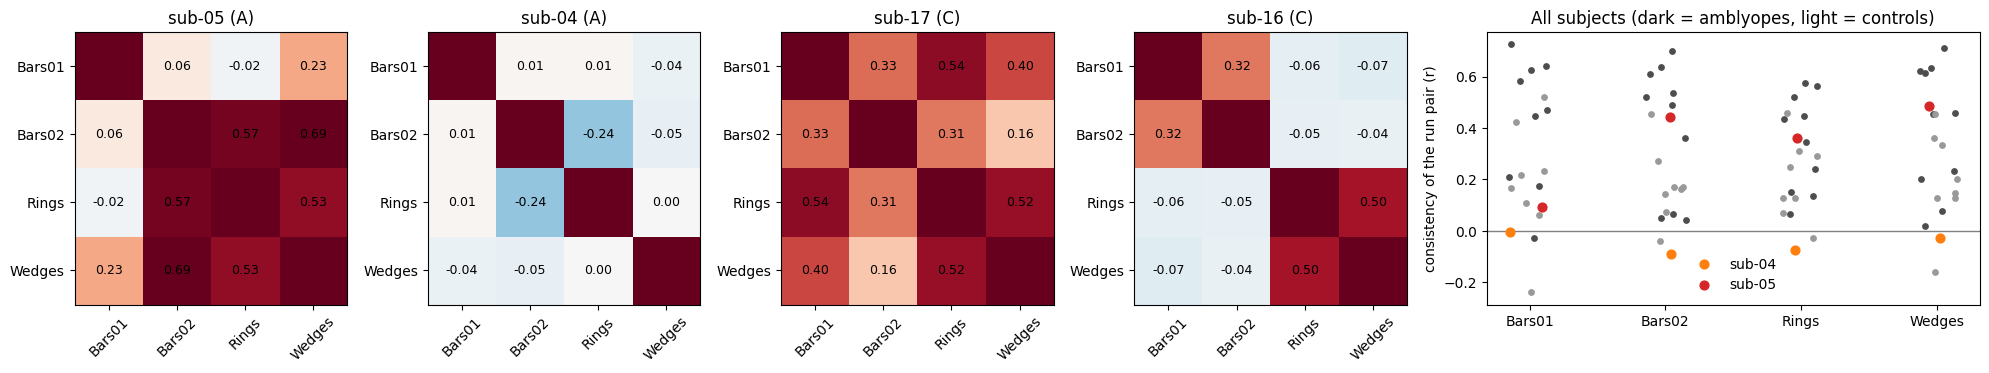

In [8]:
show = focus + [s for s in reference if s in runs]
fig, axes = plt.subplots(1, len(show) + 1, figsize=(3.6 * (len(show) + 1) + 2, 3.6),
                         gridspec_kw={'width_ratios': [1] * len(show) + [1.8]})
for ax, s in zip(axes, show):
    im = ax.imshow(C_early[s], vmin=-0.6, vmax=0.6, cmap='RdBu_r')
    for i in range(4):
        for j in range(4):
            if i != j:
                ax.text(j, i, '{:.2f}'.format(C_early[s][i, j]), ha='center', va='center', fontsize=9)
    ax.set_xticks(range(4)); ax.set_xticklabels(run_names, rotation=45)
    ax.set_yticks(range(4)); ax.set_yticklabels(run_names)
    ax.set_title(labels[s])
ax = axes[-1]
rng_e = np.random.default_rng(0)
for k, n in enumerate(run_names):
    for s in subj_order:
        v = t1.loc[labels[s], 'cons_{}'.format(n)]
        col = {'sub-05': 'tab:red', 'sub-04': 'tab:orange'}.get(s, '0.6' if s in controls else '0.3')
        ax.scatter(k + rng_e.uniform(-0.15, 0.15), v, s=40 if s in focus else 15, color=col, zorder=3 if s in focus else 2,
                   label=s if (s in focus and k == 0) else None)
ax.axhline(0, color='grey', lw=1)
ax.set_xticks(range(4)); ax.set_xticklabels(run_names)
ax.set_ylabel('consistency of the run pair (r)')
ax.legend(frameon=False)
ax.set_title('All subjects (dark = amblyopes, light = controls)')
plt.tight_layout()
fig.savefig('{}/eyecheck_E1_run_maps.pdf'.format(fig_dir), bbox_inches='tight')
plt.show()

## Test 2 — grouping of the 4 bars runs

The 4 bars runs (FE-Bars01, FE-Bars02, AE-Bars01, AE-Bars02) have the same stimulus. Each run's β map is divided by its ROI weighted mean (gain), then the mean of the 4 is removed: what is left is what differs between runs, including the eye. For the 3 ways of making 2 pairs, mean weighted correlation within the pairs; the grouping **by eye** (labelled) should win. Unlike test 1, it does not assume that the two runs of a stimulus are one FE and one AE.

In [9]:
parts = {'by eye (labelled)': [(0, 1), (2, 3)], 'by run number': [(0, 2), (1, 3)], 'crossed': [(0, 3), (1, 2)]}


def bars_partition(R, rois):
    res = {k: [] for k in parts}
    for roi in rois:
        m = R['keep'] & (R['roi'] == roi)
        if m.sum() < 10:
            continue
        w = R['w'][m]
        X = np.vstack([R['b_fe'][0, m], R['b_fe'][1, m], R['b_ae'][0, m], R['b_ae'][1, m]])
        gain = np.array([np.sum(w * x) / np.sum(w) for x in X])
        if np.any(gain <= 0):
            continue
        X = X / gain[:, None]
        X = X - X.mean(axis=0)
        for k, pairs in parts.items():
            res[k].append(np.mean([wpearson(X[a], X[b], w) for a, b in pairs]))
    return {k: fisher_mean(v) if len(v) else np.nan for k, v in res.items()}


rows = []
for s in subj_order:
    for name, rois in [('V1-V3', early), ('V4-LO2', ['V4', 'V3A', 'V3B', 'LO1', 'LO2'])]:
        r = bars_partition(runs[s], rois)
        rows.append({'subject': labels[s], 'rois': name, **r, 'winner': max(r, key=lambda k: -np.inf if np.isnan(r[k]) else r[k])})
t2 = pd.DataFrame(rows)
print(t2.pivot(index='subject', columns='rois', values='winner').reindex([labels[s] for s in subj_order]).to_string())
print()
print(t2.set_index(['subject', 'rois']).round(3).to_string())
print('\nLabelled grouping wins (V1-V3): {}/{} subjects'.format(
    (t2[t2.rois == 'V1-V3'].winner == 'by eye (labelled)').sum(), (t2.rois == 'V1-V3').sum()))

rois                    V1-V3             V4-LO2
subject                                         
sub-01 (A)  by eye (labelled)  by eye (labelled)
sub-02 (A)  by eye (labelled)  by eye (labelled)
sub-03 (A)  by eye (labelled)  by eye (labelled)
sub-04 (A)  by eye (labelled)  by eye (labelled)
sub-05 (A)  by eye (labelled)  by eye (labelled)
sub-06 (A)  by eye (labelled)  by eye (labelled)
sub-07 (A)  by eye (labelled)  by eye (labelled)
sub-08 (A)  by eye (labelled)  by eye (labelled)
sub-09 (A)  by eye (labelled)  by eye (labelled)
sub-10 (A)  by eye (labelled)  by eye (labelled)
sub-11 (A)  by eye (labelled)  by eye (labelled)
sub-12 (A)      by run number      by run number
sub-13 (C)  by eye (labelled)  by eye (labelled)
sub-14 (C)  by eye (labelled)  by eye (labelled)
sub-16 (C)  by eye (labelled)      by run number
sub-17 (C)  by eye (labelled)  by eye (labelled)
sub-18 (C)      by run number      by run number
sub-19 (C)            crossed            crossed
sub-20 (C)  by eye (

## Test 3 — fit quality of each run (hint of a global swap)

Weighted median over the V1-V3 vertices of the R² of each run with its own eye's pRF prediction, and of its β. In the amblyopes the amblyopic eye is expected to fit less well (pRF R² AE < FE in V2-LO2, `retinotopy_amblyopia.ipynb`). If sub-05's runs labelled AE fit **better** than those labelled FE while the other amblyopes show the reverse, it is a hint (not a proof) that the eyes are globally swapped.

Median over the 4 runs (V1-V3); runs_AE_better_R2 = number of stimuli where the AE-RE run fits better than the FE-LE run
              group  r2_fe  r2_ae  r2_ratio_AE/FE   b_fe   b_ae  b_ratio_AE/FE  runs_AE_better_R2
subject                                                                                          
sub-01 (A)  patient  0.702  0.674           0.960  1.792  1.638          0.914                  1
sub-02 (A)  patient  0.591  0.551           0.932  1.206  1.039          0.862                  0
sub-03 (A)  patient  0.559  0.399           0.713  1.538  1.097          0.713                  0
sub-04 (A)  patient  0.120  0.133           1.107  0.384  0.446          1.161                  2
sub-05 (A)  patient  0.404  0.512           1.267  0.823  1.087          1.321                  3
sub-06 (A)  patient  0.621  0.589           0.948  1.252  1.061          0.848                  1
sub-07 (A)  patient  0.379  0.364           0.962  0.727  0.588          0.810                 

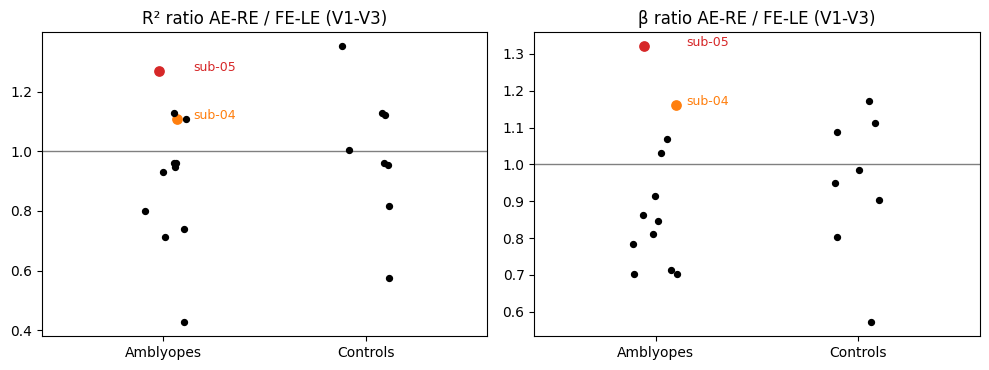

In [10]:
rows = []
for s in subj_order:
    R = runs[s]
    m = R['keep'] & np.isin(R['roi'], early)
    w = R['w'][m]
    row = {'subject': labels[s], 'group': R['group']}
    for e in ['fe', 'ae']:
        for k, n in enumerate(run_names):
            row['r2_{}_{}'.format(e, n)] = wmedian(R['r2_{}'.format(e)][k, m], w)
            row['b_{}_{}'.format(e, n)] = wmedian(R['b_{}'.format(e)][k, m], w)
        row['r2_{}'.format(e)] = np.median([row['r2_{}_{}'.format(e, n)] for n in run_names])
        row['b_{}'.format(e)] = np.median([row['b_{}_{}'.format(e, n)] for n in run_names])
    row['r2_ratio_AE/FE'] = row['r2_ae'] / row['r2_fe']
    row['b_ratio_AE/FE'] = row['b_ae'] / row['b_fe']
    row['runs_AE_better_R2'] = sum(row['r2_ae_{}'.format(n)] > row['r2_fe_{}'.format(n)] for n in run_names)
    rows.append(row)
t3 = pd.DataFrame(rows).set_index('subject')
print('Median over the 4 runs (V1-V3); runs_AE_better_R2 = number of stimuli where the AE-RE run fits better than the FE-LE run')
print(t3[['group', 'r2_fe', 'r2_ae', 'r2_ratio_AE/FE', 'b_fe', 'b_ae', 'b_ratio_AE/FE', 'runs_AE_better_R2']].round(3).to_string())
for s in focus:
    print('\n{} per run:'.format(s))
    print(pd.DataFrame({e.upper(): {n: '{:.3f} / β {:.2f}'.format(t3.loc[labels[s], 'r2_{}_{}'.format(e, n)], t3.loc[labels[s], 'b_{}_{}'.format(e, n)])
                                    for n in run_names} for e in ['fe', 'ae']}).to_string())

fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
for a, col, title in [(ax[0], 'r2_ratio_AE/FE', 'R² ratio AE-RE / FE-LE (V1-V3)'), (ax[1], 'b_ratio_AE/FE', 'β ratio AE-RE / FE-LE (V1-V3)')]:
    for g_i, g in enumerate(groups):
        d = t3[t3.group == g]
        for s, v in d[col].items():
            sub = s.split(' ')[0]
            c = {'sub-05': 'tab:red', 'sub-04': 'tab:orange'}.get(sub, 'black')
            a.scatter(g_i + rng_e.uniform(-0.12, 0.12), v, color=c, s=45 if sub in focus else 18, zorder=3)
            if sub in focus:
                a.annotate(sub, (g_i + 0.15, v), fontsize=9, color=c)
    a.axhline(1, color='grey', lw=1)
    a.set_xticks([0, 1]); a.set_xticklabels([group_labels[g] for g in groups]); a.set_xlim(-0.6, 1.6)
    a.set_title(title)
plt.tight_layout()
fig.savefig('{}/eyecheck_E3_fit_quality.pdf'.format(fig_dir), bbox_inches='tight')
plt.show()

## Test 4 — acquisition order

BIDS sidecars of the functional runs (read only): acquisition time / series number, labelled eye and stimulus, and the eye scanned first according to `sourcedata/participant-mapping.md`. With the expected protocol, the runs of one eye form a contiguous block and the first block is the eye of the notes. The names are the **relabelled** ones: for sub-05 compare also with the original names in the notes (introduction).

In [11]:
def acq_table(subject):
    fns = sorted(glob.glob('{}/{}/{}/**/func/*_bold.json'.format(main_dir, project_dir, subject), recursive=True))
    rows = []
    for fn in fns:
        try:
            with open(fn) as f:
                meta = json.load(f)
        except Exception as err:
            meta = {'error': str(err)}
        name = os.path.basename(fn)
        rows.append({'file': name.replace('{}_'.format(subject), '').replace('_bold.json', ''),
                     'eye': 'LE' if 'LeftEye' in name else 'RE' if 'RightEye' in name else '?',
                     'AcquisitionTime': meta.get('AcquisitionTime', meta.get('AcquisitionDateTime')),
                     'SeriesNumber': meta.get('SeriesNumber'), 'ProtocolName': meta.get('ProtocolName', meta.get('SeriesDescription'))})
    t = pd.DataFrame(rows)
    if len(t) and t.AcquisitionTime.notna().any():
        t = t.sort_values('AcquisitionTime')
    elif len(t) and t.SeriesNumber.notna().any():
        t = t.sort_values('SeriesNumber')
    return t


for s in focus + [r for r in reference if r in runs]:
    print('\n=== {} | amblyopic eye: {} | eye scanned first (notes): {}'.format(s, ambly_eye.get(s, '-'), first_eye.get(s, '?')))
    t = acq_table(s)
    print(t.to_string(index=False) if len(t) else 'no BIDS json found')
    if len(t):
        blocks = (t.eye != t.eye.shift()).sum()
        print('-> {} contiguous eye block(s) in acquisition order (2 expected), first block: {}'.format(blocks, t.eye.iloc[0]))


=== sub-05 | amblyopic eye: R | eye scanned first (notes): R
                             file eye AcquisitionTime  SeriesNumber           ProtocolName
   ses-01_task-BarsLeftEye_run-01  LE            None             6 WIPfMRI_RL_33_166SENSE
   ses-01_task-BarsLeftEye_run-02  LE            None             6 WIPfMRI_RL_33_166SENSE
  ses-01_task-BarsRightEye_run-01  RE            None             6 WIPfMRI_RL_33_166SENSE
  ses-01_task-BarsRightEye_run-02  RE            None             6 WIPfMRI_RL_33_166SENSE
  ses-01_task-RingsLeftEye_run-01  LE            None             6 WIPfMRI_RL_33_166SENSE
 ses-01_task-RingsRightEye_run-01  RE            None             6 WIPfMRI_RL_33_166SENSE
 ses-01_task-WedgesLeftEye_run-01  LE            None             6 WIPfMRI_RL_33_166SENSE
ses-01_task-WedgesRightEye_run-01  RE            None             6 WIPfMRI_RL_33_166SENSE
-> 6 contiguous eye block(s) in acquisition order (2 expected), first block: LE

=== sub-04 | amblyopic eye: L | eye sc

## Summary

In [12]:
summ = pd.DataFrame({
    'OD index V1': df_subjects[df_subjects.roi == 'V1'].set_index('subject').od_index.rename(index=labels),
    'OD index V2-V3 (mean)': df_subjects[df_subjects.roi.isin(['V2', 'V3'])].groupby('subject').od_index.mean().rename(index=labels),
    'T1 mean r per-run maps': t1.mean_r, 'T1 worst pair': t1.worst_pair,
    'T1 worst consistency': t1[['cons_{}'.format(n) for n in run_names]].min(axis=1),
    'T1 best flip': t1.best_flip,
    'T2 winner V1-V3': t2[t2.rois == 'V1-V3'].set_index('subject').winner,
    'T3 R² ratio AE/FE': t3['r2_ratio_AE/FE']}).reindex([labels[s] for s in subj_order])
print(summ.round(3).to_string())

            OD index V1  OD index V2-V3 (mean)  T1 mean r per-run maps T1 worst pair  T1 worst consistency           T1 best flip    T2 winner V1-V3  T3 R² ratio AE/FE
subject                                                                                                                                                                
sub-01 (A)        0.013                  0.023                   0.467        Bars01                 0.445        none (labelled)  by eye (labelled)              0.960
sub-02 (A)        0.092                  0.088                   0.581         Rings                 0.521        none (labelled)  by eye (labelled)              0.932
sub-03 (A)        0.155                  0.204                   0.656         Rings                 0.574        none (labelled)  by eye (labelled)              0.713
sub-04 (A)        0.002                 -0.052                  -0.050        Bars02                -0.092          Rings, Wedges  by eye (labelled)            

## Reading guide

- **Labels consistent** (as in the reference subjects): all run pairs with positive consistency, labelled flip best, bars grouped by eye. Then the reversal of sub-05 is either real or due to a **global** swap of the eyes, which the maps cannot detect: look at test 3 (does the labelled AE fit better than the FE, unlike the other amblyopes?) and test 4 (order of the eye blocks vs notes).
- **One pair inconsistent** (negative consistency, best flip = that stimulus, ideally in several ROIs): the two runs of that stimulus probably have swapped eyes. Effect on the OD: with 1 pair of 4 swapped, the dominance is reduced by half; with 2 of 4, it cancels.
- **Bars grouped by run number or crossed**: some bars runs have the wrong eye (case not covered by test 1).
- The correlations are noisy for a single run (1 run of each eye per map): compare with the distribution of all subjects before concluding, and only conclude on a pattern seen in several ROIs.
- Next step if a swap is found: re-run `make_od_img.py` (on the cluster) with the corrected labels, after correcting the BIDS names; nothing is changed here.